In [2]:
import os

# Search the JupyterHub home directory for CSV files
base_path = os.path.expanduser("~")

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

/home/08c3ee00-db81-45d7-82f2-63436b719152/Customer Acqusition.csv
/home/08c3ee00-db81-45d7-82f2-63436b719152/website_pageviews.csv
/home/08c3ee00-db81-45d7-82f2-63436b719152/Car_sales - 1755416548485.csv
/home/08c3ee00-db81-45d7-82f2-63436b719152/Netflix_Cleaned.csv
/home/08c3ee00-db81-45d7-82f2-63436b719152/website_sessions.csv
/home/08c3ee00-db81-45d7-82f2-63436b719152/Dataset.csv
/home/08c3ee00-db81-45d7-82f2-63436b719152/Customer.csv
/home/08c3ee00-db81-45d7-82f2-63436b719152/Transactions.csv
/home/08c3ee00-db81-45d7-82f2-63436b719152/SalesData.csv
/home/08c3ee00-db81-45d7-82f2-63436b719152/spend.csv
/home/08c3ee00-db81-45d7-82f2-63436b719152/Repayment.csv
/home/08c3ee00-db81-45d7-82f2-63436b719152/.ipynb_checkpoints/Car_sales - 1755416548485-checkpoint.csv
/home/08c3ee00-db81-45d7-82f2-63436b719152/.ipynb_checkpoints/Customer Acqusition-checkpoint.csv
/home/08c3ee00-db81-45d7-82f2-63436b719152/.ipynb_checkpoints/website_pageviews-checkpoint.csv
/home/08c3ee00-db81-45d7-82f2-63436

In [8]:
import pandas as pd
Customer = pd.read_csv("Customer.csv")
Geolocation = pd.read_csv("geolocation.csv")
Order_items = pd.read_csv("order_items.csv")
Order_Payment = pd.read_csv("order_payments.csv")
Order_reviews = pd.read_csv("order_reviews.csv")
Orders = pd.read_csv("orders.csv")
Product_category_name_translation = pd.read_csv(
    "product_category_name_translation.csv"
)
Products = pd.read_csv("products.csv")
Sellers = pd.read_csv("sellers.csv")

print("All nine datasets loaded successfully!")


All nine datasets loaded successfully!


In [9]:
import pandas as pd

# Store all nine Olist datasets in a dictionary
datasets = {
    "Customer": Customer,
    "Geolocation": Geolocation,
    "Order_Items": Order_items,
    "Order_Payment": Order_Payment,
    "Order_Reviews": Order_reviews,
    "Orders": Orders,
    "Category_Translation": Product_category_name_translation,
    "Products": Products,
    "Sellers": Sellers
}

# Display the dimensions of each dataset
print("OLIST DATASET VERIFICATION")
print("-" * 55)

for name, df in datasets.items():
    print(f"{name:<25} Rows: {df.shape[0]:>10,} | Columns: {df.shape[1]:>3}")

print("-" * 55)
print("Total datasets loaded:", len(datasets))

OLIST DATASET VERIFICATION
-------------------------------------------------------
Customer                  Rows:     99,441 | Columns:   5
Geolocation               Rows:  1,000,163 | Columns:   5
Order_Items               Rows:    112,650 | Columns:   7
Order_Payment             Rows:    103,886 | Columns:   5
Order_Reviews             Rows:     99,224 | Columns:   7
Orders                    Rows:     99,441 | Columns:   8
Category_Translation      Rows:         71 | Columns:   2
Products                  Rows:     32,951 | Columns:   9
Sellers                   Rows:      3,095 | Columns:   4
-------------------------------------------------------
Total datasets loaded: 9


In [10]:
# Import pandas for data manipulation
import pandas as pd

# Import numpy for numerical operations
import numpy as np

# Import matplotlib for visualisation
import matplotlib.pyplot as plt

# Import functions for splitting the dataset
from sklearn.model_selection import train_test_split

# Import preprocessing tools
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Import pipeline tools to combine preprocessing and modelling
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Import machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("All required libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


All required libraries imported successfully!


In [11]:
# Organise all nine datasets into a dictionary

datasets = {
    "Customer": Customer,
    "Geolocation": Geolocation,
    "Order_Items": Order_items,
    "Order_Payment": Order_Payment,
    "Order_Reviews": Order_reviews,
    "Orders": Orders,
    "Category_Translation": Product_category_name_translation,
    "Products": Products,
    "Sellers": Sellers
}

# Display the number of rows and columns in each dataset

print("OLIST DATASET VERIFICATION")
print("-" * 55)

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

print("-" * 55)
print("Total datasets available:", len(datasets))

OLIST DATASET VERIFICATION
-------------------------------------------------------
Customer: (99441, 5)
Geolocation: (1000163, 5)
Order_Items: (112650, 7)
Order_Payment: (103886, 5)
Order_Reviews: (99224, 7)
Orders: (99441, 8)
Category_Translation: (71, 2)
Products: (32951, 9)
Sellers: (3095, 4)
-------------------------------------------------------
Total datasets available: 9


In [ ]:
## Understand our prediction objective
Our business question is:

Can we classify whether an order was delivered later than its estimated delivery date?

We'll use binary classification.
Target value	Meaning
0	Delivered on or before the estimated date
1	Delivered after the estimated date


The actual delivery date will help us create the target, but we must not use it as a model input.

In [12]:
# Create copies of the datasets required for modelling

orders_model = Orders.copy()
items_model = Order_items.copy()
products_model = Products.copy()
sellers_model = Sellers.copy()

print("Modelling copies created successfully!")

Modelling copies created successfully!


In [13]:
# Identify the relevant timestamp columns

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

# Convert the columns into datetime format

for column in date_columns:
    orders_model[column] = pd.to_datetime(
        orders_model[column],
        errors="coerce"
    )

# Display the resulting data types

print(orders_model[date_columns].dtypes)

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [14]:
# Keep delivered orders with both delivery dates available

model_data = orders_model[
    (orders_model["order_status"] == "delivered")
    & orders_model["order_delivered_customer_date"].notna()
    & orders_model["order_estimated_delivery_date"].notna()
].copy()

# Display the number of eligible orders

print("Eligible orders for modelling:", len(model_data))

Eligible orders for modelling: 96470


In [15]:
# Create a binary target:
# 1 = actual delivery occurred after the estimated date
# 0 = actual delivery occurred on or before the estimated date

model_data["late_delivery"] = (
    model_data["order_delivered_customer_date"]
    > model_data["order_estimated_delivery_date"]
).astype(int)

# Display the number of orders in each class

print("Late delivery target distribution:")
print(model_data["late_delivery"].value_counts())

# Display the percentage of each class

print("\nTarget distribution in percentage:")

print(
    (model_data["late_delivery"].value_counts(normalize=True) * 100)
    .round(2)
)

Late delivery target distribution:
late_delivery
0    88644
1     7826
Name: count, dtype: int64

Target distribution in percentage:
late_delivery
0    91.89
1     8.11
Name: proportion, dtype: float64


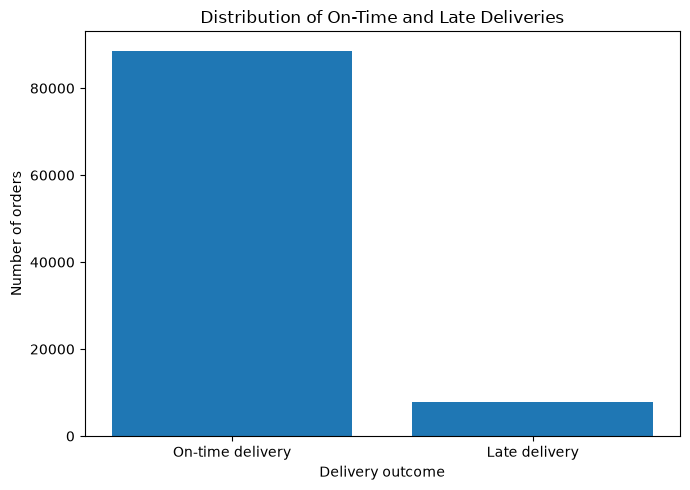

In [16]:
# Count the orders in each target category

target_counts = model_data["late_delivery"].value_counts().sort_index()

# Create labels for the chart

target_labels = ["On-time delivery", "Late delivery"]

# Plot the distribution

plt.figure(figsize=(7, 5))

plt.bar(
    target_labels,
    [target_counts.get(0, 0), target_counts.get(1, 0)]
)

plt.title("Distribution of On-Time and Late Deliveries")
plt.xlabel("Delivery outcome")
plt.ylabel("Number of orders")

plt.tight_layout()
plt.show()

In [17]:
# Extract the purchase month

model_data["purchase_month"] = (
    model_data["order_purchase_timestamp"].dt.month
)

# Extract the day of the week
# Monday = 0, Sunday = 6

model_data["purchase_day_of_week"] = (
    model_data["order_purchase_timestamp"].dt.dayofweek
)

# Extract the purchase hour

model_data["purchase_hour"] = (
    model_data["order_purchase_timestamp"].dt.hour
)

# Calculate the promised delivery interval in days

model_data["promised_delivery_days"] = (
    model_data["order_estimated_delivery_date"]
    - model_data["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Display the engineered features

display(
    model_data[
        [
            "purchase_month",
            "purchase_day_of_week",
            "purchase_hour",
            "promised_delivery_days",
            "late_delivery"
        ]
    ].head()
)

,purchase_month,purchase_day_of_week,purchase_hour,promised_delivery_days,late_delivery
0,10,0,10,15.544444,0
1,7,1,20,19.138194,0
2,8,2,8,26.640278,0
3,11,5,19,26.188889,0
4,2,1,21,12.112500,0


In [18]:
# Convert price and freight columns to numeric values

items_model["price"] = pd.to_numeric(
    items_model["price"],
    errors="coerce"
)

items_model["freight_value"] = pd.to_numeric(
    items_model["freight_value"],
    errors="coerce"
)

# Aggregate item information at the order level

order_item_features = (
    items_model.groupby("order_id")
    .agg(
        item_count=("order_item_id", "count"),
        total_item_price=("price", "sum"),
        total_freight_value=("freight_value", "sum"),
        unique_sellers=("seller_id", "nunique"),
        unique_products=("product_id", "nunique")
    )
    .reset_index()
)

# Check the aggregated data

display(order_item_features.head())

print("Aggregated order records:", len(order_item_features))

,order_id,item_count,total_item_price,total_freight_value,unique_sellers,unique_products
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29,1,1
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93,1,1
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87,1,1
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79,1,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14,1,1


Aggregated order records: 98666


In [19]:
# Merge the order-level item features into the modelling dataset

model_data = model_data.merge(
    order_item_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Check the result

print("Modelling dataset shape:", model_data.shape)

display(
    model_data[
        [
            "order_id",
            "item_count",
            "total_item_price",
            "total_freight_value",
            "unique_sellers",
            "unique_products",
            "late_delivery"
        ]
    ].head()
)

Modelling dataset shape: (96470, 18)


,order_id,item_count,total_item_price,total_freight_value,unique_sellers,unique_products,late_delivery
0,e481f51cbdc54678b7cc49136f2d6af7,1,29.99,8.72,1,1,0
1,53cdb2fc8bc7dce0b6741e2150273451,1,118.70,22.76,1,1,0
2,47770eb9100c2d0c44946d9cf07ec65d,1,159.90,19.22,1,1,0
3,949d5b44dbf5de918fe9c16f97b45f8a,1,45.00,27.20,1,1,0
4,ad21c59c0840e6cb83a9ceb5573f8159,1,19.90,8.72,1,1,0


In [20]:
# Attach English category names to the product records

products_model = products_model.merge(
    Product_category_name_translation,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

# Attach product categories to order items

item_category = items_model[
    ["order_id", "product_id"]
].merge(
    products_model[
        ["product_id", "product_category_name_english"]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Select the most common product category for each order

def get_main_category(series):
    # Replace missing category labels before finding the mode
    series = series.fillna("unknown")

    # Return the most common category
    modes = series.mode()

    if modes.empty:
        return "unknown"

    return modes.iloc[0]


order_category = (
    item_category.groupby("order_id")[
        "product_category_name_english"
    ]
    .agg(get_main_category)
    .reset_index()
    .rename(
        columns={
            "product_category_name_english": "main_product_category"
        }
    )
)

# Merge the category information into the modelling dataset

model_data = model_data.merge(
    order_category,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Product category feature added.")

display(
    model_data[
        ["order_id", "main_product_category", "late_delivery"]
    ].head()
)

Product category feature added.


,order_id,main_product_category,late_delivery
0,e481f51cbdc54678b7cc49136f2d6af7,housewares,0
1,53cdb2fc8bc7dce0b6741e2150273451,perfumery,0
2,47770eb9100c2d0c44946d9cf07ec65d,auto,0
3,949d5b44dbf5de918fe9c16f97b45f8a,pet_shop,0
4,ad21c59c0840e6cb83a9ceb5573f8159,stationery,0


In [21]:
# Select the seller identifier and state

seller_features = sellers_model[
    ["seller_id", "seller_state"]
].copy()

# Attach seller states to order items

order_seller_state = items_model[
    ["order_id", "seller_id"]
].merge(
    seller_features,
    on="seller_id",
    how="left",
    validate="many_to_one"
)

# Select the most common seller state for each order

order_seller_state = (
    order_seller_state.groupby("order_id")["seller_state"]
    .agg(get_main_category)
    .reset_index()
    .rename(columns={"seller_state": "main_seller_state"})
)

# Merge seller location into the modelling dataset

model_data = model_data.merge(
    order_seller_state,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Seller location feature added.")

display(
    model_data[
        ["order_id", "main_seller_state", "late_delivery"]
    ].head()
)

Seller location feature added.


,order_id,main_seller_state,late_delivery
0,e481f51cbdc54678b7cc49136f2d6af7,SP,0
1,53cdb2fc8bc7dce0b6741e2150273451,SP,0
2,47770eb9100c2d0c44946d9cf07ec65d,SP,0
3,949d5b44dbf5de918fe9c16f97b45f8a,MG,0
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,0


In [22]:
# Numerical features

numeric_features = [
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",
    "promised_delivery_days",
    "item_count",
    "total_item_price",
    "total_freight_value",
    "unique_sellers",
    "unique_products"
]

# Categorical features

categorical_features = [
    "main_product_category",
    "main_seller_state"
]

# Combine the feature names

feature_columns = numeric_features + categorical_features

# Create the feature matrix

X = model_data[feature_columns].copy()

# Create the target vector

y = model_data["late_delivery"].copy()

# Standardise missing category labels

for column in categorical_features:
    X[column] = X[column].fillna("unknown").astype(str)

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nSelected features:")
print(feature_columns)

Feature matrix shape: (96470, 11)
Target vector shape: (96470,)

Selected features:
['purchase_month', 'purchase_day_of_week', 'purchase_hour', 'promised_delivery_days', 'item_count', 'total_item_price', 'total_freight_value', 'unique_sellers', 'unique_products', 'main_product_category', 'main_seller_state']


In [23]:
# Split the dataset into training and testing portions

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training records: 77176
Testing records: 19294

Training target distribution:
late_delivery
0    0.919
1    0.081
Name: proportion, dtype: float64

Testing target distribution:
late_delivery
0    0.919
1    0.081
Name: proportion, dtype: float64


In [24]:
# Prepare numerical features:
# 1. Fill missing values with the median.
# 2. Standardise the numerical values.

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Prepare categorical features:
# 1. Fill missing values with the most frequent category.
# 2. Convert categories into numeric indicator variables.

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Apply the appropriate transformation to each feature group

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [25]:
# Create a baseline classifier that always predicts the
# most frequent class in the training data.

baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# Fit the baseline model

baseline_model.fit(X_train, y_train)

# Generate predictions on the test set

baseline_predictions = baseline_model.predict(X_test)

# Calculate baseline accuracy

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print(f"Baseline accuracy: {baseline_accuracy:.4f}")

Baseline accuracy: 0.9189


In [26]:
# Create a pipeline that preprocesses the data and trains
# the logistic regression classifier.

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

# Train the complete pipeline on the training data

model.fit(X_train, y_train)

print("Logistic regression model trained successfully!")

Logistic regression model trained successfully!


In [27]:
# Predict the class of each order in the test set

y_pred = model.predict(X_test)

# Calculate the predicted probability of late delivery

y_probability = model.predict_proba(X_test)[:, 1]

# Display a small sample of predictions

prediction_results = pd.DataFrame({
    "Actual_Late_Delivery": y_test.to_numpy(),
    "Predicted_Late_Delivery": y_pred,
    "Predicted_Late_Probability": y_probability
})

display(prediction_results.head(10))

,Actual_Late_Delivery,Predicted_Late_Delivery,Predicted_Late_Probability
0,0,1,0.546290
1,0,1,0.538088
2,0,0,0.467502
3,0,1,0.517356
4,0,0,0.366475
5,0,0,0.356219
6,0,0,0.343746
7,0,1,0.594078
8,0,0,0.449058
9,0,0,0.456822


In [28]:
# Calculate the main classification metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_probability
)

# Display the results

print("MODEL PERFORMANCE")
print("=" * 45)

print(f"Baseline Accuracy : {baseline_accuracy:.4f}")
print(f"Model Accuracy    : {accuracy:.4f}")
print(f"Precision         : {precision:.4f}")
print(f"Recall            : {recall:.4f}")
print(f"F1-score          : {f1:.4f}")
print(f"ROC-AUC           : {roc_auc:.4f}")

MODEL PERFORMANCE
Baseline Accuracy : 0.9189
Model Accuracy    : 0.5580
Precision         : 0.1096
Recall            : 0.6243
F1-score          : 0.1864
ROC-AUC           : 0.6206


In [29]:
# Display precision, recall, F1-score, and support for each class

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["On-time", "Late"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

     On-time       0.94      0.55      0.70     17729
        Late       0.11      0.62      0.19      1565

    accuracy                           0.56     19294
   macro avg       0.53      0.59      0.44     19294
weighted avg       0.88      0.56      0.66     19294



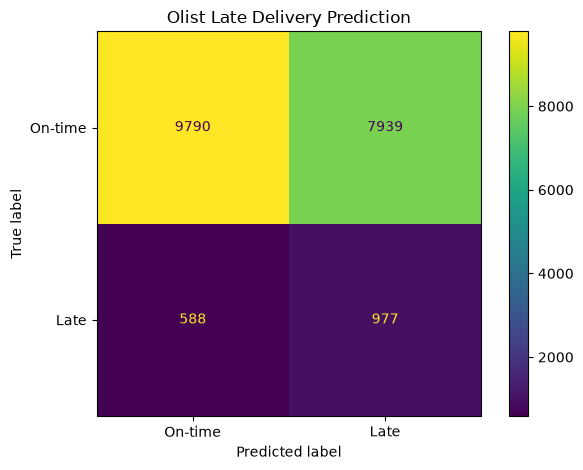

In [30]:
# Compare actual outcomes with predicted outcomes

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["On-time", "Late"],
    values_format="d"
)

plt.title("Olist Late Delivery Prediction")
plt.tight_layout()
plt.show()

In [31]:
# Organise the model metrics into a table for documentation

results = pd.DataFrame({
    "Metric": [
        "Baseline Accuracy",
        "Model Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Value": [
        baseline_accuracy,
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

# Display the final results

display(results)

,Metric,Value
0,Baseline Accuracy,0.918887
1,Model Accuracy,0.558049
2,Precision,0.109578
3,Recall,0.624281
4,F1-score,0.186433
5,ROC-AUC,0.620554


In [32]:
# Import joblib for saving Python objects

import joblib

# Save the trained pipeline

joblib.dump(
    model,
    "olist_late_delivery_model.joblib"
)

print("Trained model saved successfully!")

Trained model saved successfully!


In [33]:
# Import the confusion matrix function
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the matrix
print("Confusion Matrix:")
print(cm)

# Extract the four outcomes
tn, fp, fn, tp = cm.ravel()

print("\nPrediction Breakdown")
print("-" * 40)
print("Correctly predicted on-time orders:", tn)
print("On-time orders incorrectly flagged as late:", fp)
print("Late orders incorrectly classified as on-time:", fn)
print("Correctly predicted late orders:", tp)

Confusion Matrix:
[[9790 7939]
 [ 588  977]]

Prediction Breakdown
----------------------------------------
Correctly predicted on-time orders: 9790
On-time orders incorrectly flagged as late: 7939
Late orders incorrectly classified as on-time: 588
Correctly predicted late orders: 977


In [35]:
# Import the required evaluation metrics
from sklearn.metrics import precision_score, recall_score, f1_score

# Test different probability thresholds
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

print("THRESHOLD COMPARISON")
print("-" * 75)

for threshold in thresholds:

    # Classify an order as late if its probability meets the threshold
    threshold_predictions = (y_probability >= threshold).astype(int)

    # Calculate evaluation metrics
    precision = precision_score(
        y_test, threshold_predictions, zero_division=0
    )

    recall = recall_score(
        y_test, threshold_predictions, zero_division=0
    )

    f1 = f1_score(
        y_test, threshold_predictions, zero_division=0
    )

    # Display results
    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1-score: {f1:.3f}"
    )

THRESHOLD COMPARISON
---------------------------------------------------------------------------
Threshold: 0.30 | Precision: 0.084 | Recall: 0.982 | F1-score: 0.156
Threshold: 0.40 | Precision: 0.091 | Recall: 0.900 | F1-score: 0.166
Threshold: 0.50 | Precision: 0.110 | Recall: 0.624 | F1-score: 0.186
Threshold: 0.60 | Precision: 0.139 | Recall: 0.171 | F1-score: 0.153
Threshold: 0.70 | Precision: 0.197 | Recall: 0.040 | F1-score: 0.067
Threshold: 0.80 | Precision: 0.247 | Recall: 0.013 | F1-score: 0.024


In [36]:
# Import Logistic Regression and Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create a new model without class weighting
model_no_weight = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model using the same training data
model_no_weight.fit(X_train, y_train)

# Generate predictions and late-delivery probabilities
y_pred_no_weight = model_no_weight.predict(X_test)
y_probability_no_weight = model_no_weight.predict_proba(X_test)[:, 1]

print("Second model trained successfully.")

Second model trained successfully.


In [37]:
# Import evaluation metrics
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

# Evaluate the original balanced model
print("ORIGINAL MODEL — BALANCED")
print("-" * 45)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

# Evaluate the new unweighted model
print("\nNEW MODEL — NO CLASS WEIGHT")
print("-" * 45)
print("Accuracy:", round(accuracy_score(y_test, y_pred_no_weight), 4))
print("Precision:", round(precision_score(y_test, y_pred_no_weight, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_no_weight, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_no_weight, zero_division=0), 4))

# Display the new model's confusion matrix
print("\nConfusion Matrix — No Class Weight")
print(confusion_matrix(y_test, y_pred_no_weight))

ORIGINAL MODEL — BALANCED
---------------------------------------------
Accuracy: 0.558
Precision: 0.1096
Recall: 0.6243
F1-score: 0.1864

NEW MODEL — NO CLASS WEIGHT
---------------------------------------------
Accuracy: 0.9188
Precision: 0.25
Recall: 0.0006
F1-score: 0.0013

Confusion Matrix — No Class Weight
[[17726     3]
 [ 1564     1]]


In [38]:
# Count the actual classes in the training data
print("TRAINING DATA CLASS DISTRIBUTION")
print("-" * 40)

print(y_train.value_counts())

# Display the percentage of each class
print("\nTRAINING DATA CLASS PERCENTAGES")
print("-" * 40)

print(
    (y_train.value_counts(normalize=True) * 100).round(2)
)

# Count the actual classes in the test data
print("\nTEST DATA CLASS DISTRIBUTION")
print("-" * 40)

print(y_test.value_counts())

# Display the percentage of each class
print("\nTEST DATA CLASS PERCENTAGES")
print("-" * 40)

print(
    (y_test.value_counts(normalize=True) * 100).round(2)
)

TRAINING DATA CLASS DISTRIBUTION
----------------------------------------
late_delivery
0    70915
1     6261
Name: count, dtype: int64

TRAINING DATA CLASS PERCENTAGES
----------------------------------------
late_delivery
0    91.89
1     8.11
Name: proportion, dtype: float64

TEST DATA CLASS DISTRIBUTION
----------------------------------------
late_delivery
0    17729
1     1565
Name: count, dtype: int64

TEST DATA CLASS PERCENTAGES
----------------------------------------
late_delivery
0    91.89
1     8.11
Name: proportion, dtype: float64


In [39]:
# Import the Random Forest algorithm and Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create a Random Forest classification pipeline
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=10,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model using the training data
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [40]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Generate predictions on unseen test data
y_pred_rf = rf_model.predict(X_test)

# Calculate the probability of late delivery
y_probability_rf = rf_model.predict_proba(X_test)[:, 1]

# Display evaluation metrics
print("RANDOM FOREST MODEL EVALUATION")
print("-" * 45)

print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_rf, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_probability_rf), 4))

# Display the confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

RANDOM FOREST MODEL EVALUATION
---------------------------------------------
Accuracy: 0.8177
Precision: 0.2236
Recall: 0.5048
F1-score: 0.3099
ROC-AUC: 0.7506

Confusion Matrix:
[[14986  2743]
 [  775   790]]


In [41]:
# Import the evaluation metrics
from sklearn.metrics import precision_score, recall_score, f1_score

# Define the probability thresholds to test
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

print("RANDOM FOREST — THRESHOLD COMPARISON")
print("-" * 80)

for threshold in thresholds:

    # Convert probabilities into binary predictions
    threshold_predictions = (
        y_probability_rf >= threshold
    ).astype(int)

    # Calculate evaluation metrics
    precision = precision_score(
        y_test, threshold_predictions, zero_division=0
    )

    recall = recall_score(
        y_test, threshold_predictions, zero_division=0
    )

    f1 = f1_score(
        y_test, threshold_predictions, zero_division=0
    )

    # Display results for this threshold
    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1-score: {f1:.4f}"
    )

RANDOM FOREST — THRESHOLD COMPARISON
--------------------------------------------------------------------------------
Threshold: 0.30 | Precision: 0.1087 | Recall: 0.8914 | F1-score: 0.1938
Threshold: 0.40 | Precision: 0.1628 | Recall: 0.6978 | F1-score: 0.2640
Threshold: 0.50 | Precision: 0.2236 | Recall: 0.5048 | F1-score: 0.3099
Threshold: 0.60 | Precision: 0.2979 | Recall: 0.3329 | F1-score: 0.3144
Threshold: 0.70 | Precision: 0.3319 | Recall: 0.1438 | F1-score: 0.2006
Threshold: 0.80 | Precision: 0.4000 | Recall: 0.0026 | F1-score: 0.0051


In [42]:
# Import the confusion matrix function
from sklearn.metrics import confusion_matrix

# Choose the candidate threshold
chosen_threshold = 0.60

# Generate predictions using the selected threshold
y_pred_rf_060 = (
    y_probability_rf >= chosen_threshold
).astype(int)

# Calculate the confusion matrix
cm_rf_060 = confusion_matrix(y_test, y_pred_rf_060)

print("RANDOM FOREST — THRESHOLD 0.60")
print("-" * 45)
print(cm_rf_060)

# Extract the four outcomes
tn, fp, fn, tp = cm_rf_060.ravel()

print("\nPrediction Breakdown")
print("-" * 45)
print("Correctly predicted on-time orders:", tn)
print("On-time orders incorrectly flagged as late:", fp)
print("Late orders incorrectly classified as on-time:", fn)
print("Correctly predicted late orders:", tp)

RANDOM FOREST — THRESHOLD 0.60
---------------------------------------------
[[16501  1228]
 [ 1044   521]]

Prediction Breakdown
---------------------------------------------
Correctly predicted on-time orders: 16501
On-time orders incorrectly flagged as late: 1228
Late orders incorrectly classified as on-time: 1044
Correctly predicted late orders: 521


In [44]:
# Import permutation importance
from sklearn.inspection import permutation_importance
import pandas as pd

# Calculate permutation importance on the test data
importance_results = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create a table of feature importance results
feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": importance_results.importances_mean,
    "Importance_Std": importance_results.importances_std
})

# Sort features from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

# Display the results
print("RANDOM FOREST — PERMUTATION IMPORTANCE")
print("-" * 60)

print(feature_importance.round(4))

RANDOM FOREST — PERMUTATION IMPORTANCE
------------------------------------------------------------
                   Feature  Importance_Mean  Importance_Std
0           purchase_month           0.1290          0.0054
1   promised_delivery_days           0.0840          0.0037
2      total_freight_value           0.0630          0.0040
3        main_seller_state           0.0297          0.0036
4    main_product_category           0.0091          0.0010
5         total_item_price           0.0068          0.0007
6               item_count           0.0064          0.0009
7            purchase_hour           0.0033          0.0013
8           unique_sellers           0.0029          0.0009
9     purchase_day_of_week           0.0025          0.0006
10         unique_products           0.0012          0.0004


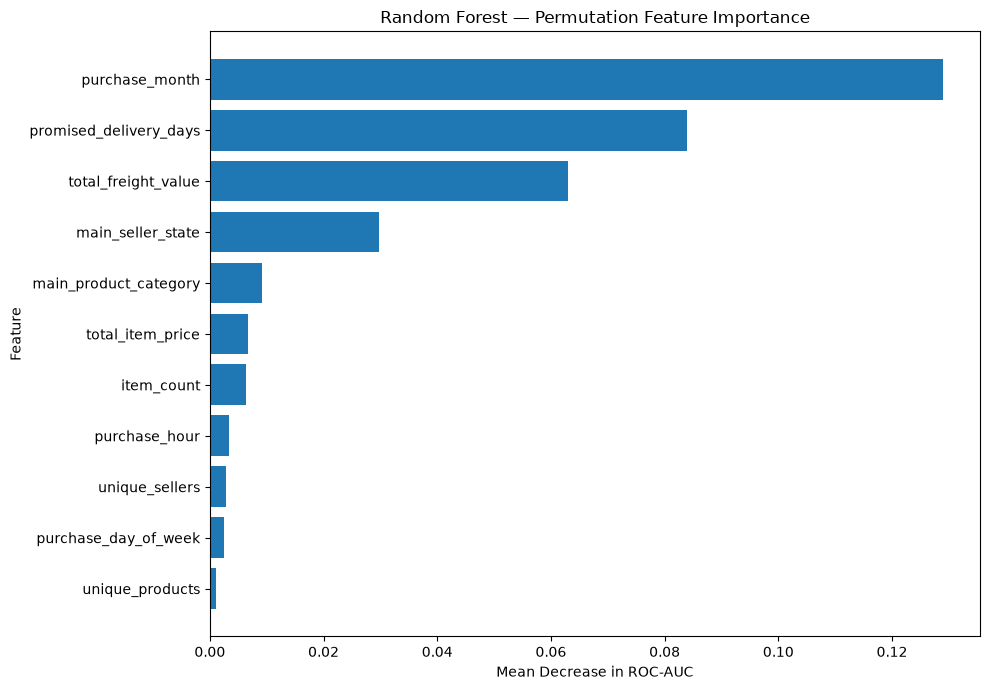

In [45]:
# Import the plotting library
import matplotlib.pyplot as plt

# Sort features for a horizontal bar chart
plot_data = feature_importance.sort_values(
    by="Importance_Mean",
    ascending=True
)

# Create the chart
plt.figure(figsize=(10, 7))

plt.barh(
    plot_data["Feature"],
    plot_data["Importance_Mean"]
)

# Add chart title and axis labels
plt.title("Random Forest — Permutation Feature Importance")
plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Feature")

# Improve layout
plt.tight_layout()

# Display the chart
plt.show()

In [46]:
# Group orders by purchase month and calculate delivery statistics
monthly_delivery = (
    model_data.groupby("purchase_month")["late_delivery"]
    .agg(
        Total_Orders="count",
        Late_Orders="sum",
        Late_Delivery_Rate="mean"
    )
    .reset_index()
)

# Convert the rate into a percentage
monthly_delivery["Late_Delivery_Rate"] = (
    monthly_delivery["Late_Delivery_Rate"] * 100
)

# Display the results
print("MONTHLY LATE-DELIVERY ANALYSIS")
print("-" * 55)

print(monthly_delivery.round(2).to_string(index=False))

MONTHLY LATE-DELIVERY ANALYSIS
-------------------------------------------------------
 purchase_month  Total_Orders  Late_Orders  Late_Delivery_Rate
              1          7819          487                6.23
              2          8208         1101               13.41
              3          9549         1638               17.15
              4          9101          542                5.96
              5         10294          684                6.64
              6          9231          204                2.21
              7         10028          409                4.08
              8         10544          799                7.58
              9          4151          217                5.23
             10          4743          240                5.06
             11          7288         1043               14.31
             12          5514          462                8.38


In [47]:
# Group orders by purchase month and calculate delivery statistics
monthly_delivery = (
    model_data.groupby("purchase_month")["late_delivery"]
    .agg(
        Total_Orders="count",
        Late_Orders="sum",
        Late_Delivery_Rate="mean"
    )
    .reset_index()
)

# Convert the rate into a percentage
monthly_delivery["Late_Delivery_Rate"] *= 100

# Display the results
print("MONTHLY LATE-DELIVERY ANALYSIS")
print("-" * 55)

print(monthly_delivery.round(2).to_string(index=False))

MONTHLY LATE-DELIVERY ANALYSIS
-------------------------------------------------------
 purchase_month  Total_Orders  Late_Orders  Late_Delivery_Rate
              1          7819          487                6.23
              2          8208         1101               13.41
              3          9549         1638               17.15
              4          9101          542                5.96
              5         10294          684                6.64
              6          9231          204                2.21
              7         10028          409                4.08
              8         10544          799                7.58
              9          4151          217                5.23
             10          4743          240                5.06
             11          7288         1043               14.31
             12          5514          462                8.38


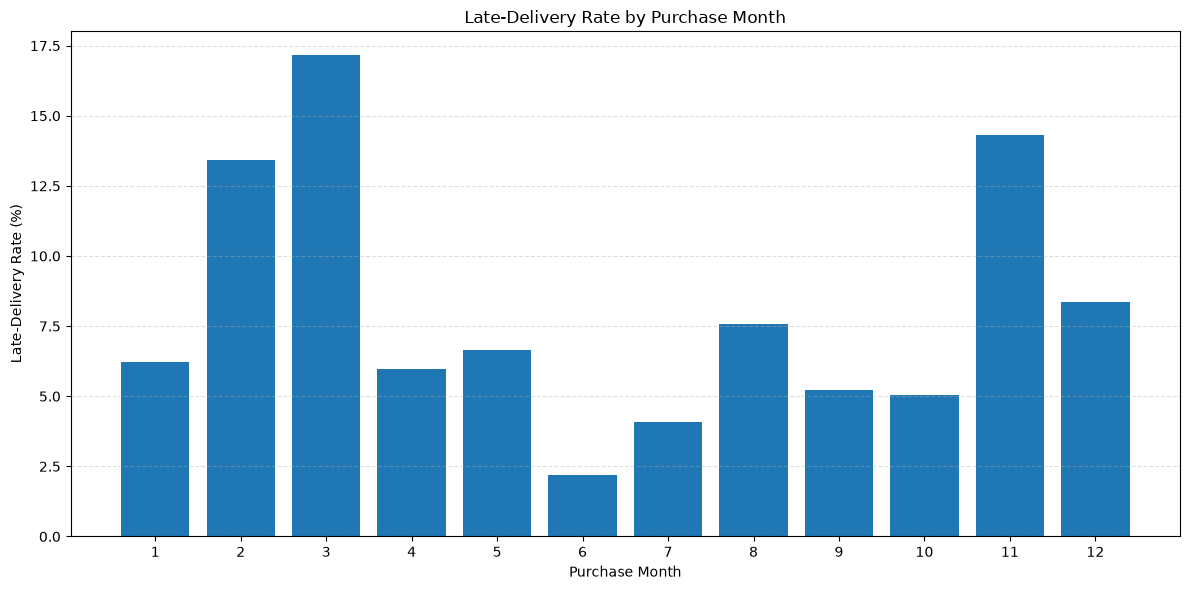

In [48]:
# Import the visualization library
import matplotlib.pyplot as plt

# Sort the months chronologically
monthly_plot = monthly_delivery.sort_values("purchase_month")

# Create a bar chart
plt.figure(figsize=(12, 6))

plt.bar(
    monthly_plot["purchase_month"],
    monthly_plot["Late_Delivery_Rate"]
)

# Add chart details
plt.title("Late-Delivery Rate by Purchase Month")
plt.xlabel("Purchase Month")
plt.ylabel("Late-Delivery Rate (%)")
plt.xticks(range(1, 13))
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [49]:
# Sort months from highest to lowest late-delivery rate
monthly_ranking = monthly_delivery.sort_values(
    "Late_Delivery_Rate",
    ascending=False
)

# Display the three highest-rate months
print("TOP 3 MONTHS BY LATE-DELIVERY RATE")
print("-" * 45)

print(
    monthly_ranking[
        ["purchase_month", "Total_Orders", "Late_Orders",
         "Late_Delivery_Rate"]
    ].head(3).round(2).to_string(index=False)
)

# Display the three lowest-rate months
print("\nBOTTOM 3 MONTHS BY LATE-DELIVERY RATE")
print("-" * 45)

print(
    monthly_ranking[
        ["purchase_month", "Total_Orders", "Late_Orders",
         "Late_Delivery_Rate"]
    ].tail(3).round(2).to_string(index=False)
)

TOP 3 MONTHS BY LATE-DELIVERY RATE
---------------------------------------------
 purchase_month  Total_Orders  Late_Orders  Late_Delivery_Rate
              3          9549         1638               17.15
             11          7288         1043               14.31
              2          8208         1101               13.41

BOTTOM 3 MONTHS BY LATE-DELIVERY RATE
---------------------------------------------
 purchase_month  Total_Orders  Late_Orders  Late_Delivery_Rate
             10          4743          240                5.06
              7         10028          409                4.08
              6          9231          204                2.21


In [50]:
# Import pandas
import pandas as pd

# Define the features used in our earlier model
feature_columns = [
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",
    "promised_delivery_days",
    "item_count",
    "total_item_price",
    "total_freight_value",
    "unique_sellers",
    "unique_products",
    "main_product_category",
    "main_seller_state"
]

# Check that the required columns exist
required_columns = (
    feature_columns
    + ["late_delivery", "order_purchase_timestamp"]
)

missing_columns = [
    column for column in required_columns
    if column not in model_data.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
else:
    print("All required columns are available.")

# Check the target distribution
print("\nTarget distribution:")
print(model_data["late_delivery"].value_counts())

print("\nTarget percentages:")
print(
    (model_data["late_delivery"].value_counts(normalize=True) * 100)
    .round(2)
)

# Check the purchase date range
model_data["order_purchase_timestamp"] = pd.to_datetime(
    model_data["order_purchase_timestamp"],
    errors="coerce"
)

print("\nPurchase date range:")
print("Earliest:", model_data["order_purchase_timestamp"].min())
print("Latest:", model_data["order_purchase_timestamp"].max())

All required columns are available.

Target distribution:
late_delivery
0    88644
1     7826
Name: count, dtype: int64

Target percentages:
late_delivery
0    91.89
1     8.11
Name: proportion, dtype: float64

Purchase date range:
Earliest: 2016-09-15 12:16:00
Latest: 2018-08-29 15:00:00


In [53]:
# Keep only rows with a valid purchase timestamp and target
model_data_time = model_data.dropna(
    subset=["order_purchase_timestamp", "late_delivery"]
).copy()

# Sort orders from earliest to latest
model_data_time = model_data_time.sort_values(
    "order_purchase_timestamp"
).reset_index(drop=True)

# Define the split boundaries
n_rows = len(model_data_time)

train_end = int(n_rows * 0.70)
validation_end = int(n_rows * 0.85)

# Create the three chronological datasets
train_data = model_data_time.iloc[:train_end].copy()

validation_data = model_data_time.iloc[
    train_end:validation_end
].copy()

test_data = model_data_time.iloc[validation_end:].copy()

# Display dataset sizes and date ranges
for name, data in [
    ("Training", train_data),
    ("Validation", validation_data),
    ("Final Test", test_data)
]:
    print(f"\n{name} dataset")
    print("-" * 40)
    print("Rows:", len(data))
    print("Start:", data["order_purchase_timestamp"].min())
    print("End:", data["order_purchase_timestamp"].max())
    print("Late-delivery rate:",
          round(data["late_delivery"].mean() * 100, 2), "%")


Training dataset
----------------------------------------
Rows: 67529
Start: 2016-09-15 12:16:00
End: 2018-04-15 20:12:00
Late-delivery rate: 9.03 %

Validation dataset
----------------------------------------
Rows: 14470
Start: 2018-04-15 20:17:00
End: 2018-06-21 08:29:00
Late-delivery rate: 5.34 %

Final Test dataset
----------------------------------------
Rows: 14471
Start: 2018-06-21 08:41:00
End: 2018-08-29 15:00:00
Late-delivery rate: 6.61 %


In [54]:
# Separate input features and target for each dataset
X_train_time = train_data[feature_columns].copy()
y_train_time = train_data["late_delivery"].astype(int)

X_validation = validation_data[feature_columns].copy()
y_validation = validation_data["late_delivery"].astype(int)

X_test_time = test_data[feature_columns].copy()
y_test_time = test_data["late_delivery"].astype(int)

# Define numeric and categorical columns
numeric_features = [
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",
    "promised_delivery_days",
    "item_count",
    "total_item_price",
    "total_freight_value",
    "unique_sellers",
    "unique_products"
]

categorical_features = [
    "main_product_category",
    "main_seller_state"
]

# Confirm the dimensions
print("Training features:", X_train_time.shape)
print("Validation features:", X_validation.shape)
print("Final test features:", X_test_time.shape)

print("\nFeature preparation complete.")

Training features: (67529, 11)
Validation features: (14470, 11)
Final test features: (14471, 11)

Feature preparation complete.


In [55]:
# Import preprocessing tools
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Import the Random Forest algorithm
from sklearn.ensemble import RandomForestClassifier

# Prepare numeric features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine the preprocessing steps
preprocessor_time = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Create the full model pipeline
rf_time_model = Pipeline(steps=[
    ("preprocessor", preprocessor_time),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=10,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

print("Time-based Random Forest pipeline created.")

Time-based Random Forest pipeline created.


In [58]:
# Train using only the training dataset
rf_time_model.fit(X_train_time, y_train_time)

print("Time-based Random Forest trained successfully.")

Time-based Random Forest trained successfully.


In [59]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Generate validation predictions at the default threshold
validation_probabilities = rf_time_model.predict_proba(
    X_validation
)[:, 1]

validation_predictions = (
    validation_probabilities >= 0.50
).astype(int)

# Display evaluation metrics
print("TIME-BASED VALIDATION RESULTS")
print("-" * 45)

print("Accuracy:",
      round(accuracy_score(y_validation, validation_predictions), 4))

print("Precision:",
      round(precision_score(
          y_validation, validation_predictions, zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_validation, validation_predictions, zero_division=0
      ), 4))

print("F1-score:",
      round(f1_score(
          y_validation, validation_predictions, zero_division=0
      ), 4))

# ROC-AUC requires both classes to be present
if y_validation.nunique() == 2:
    print("ROC-AUC:",
          round(roc_auc_score(
              y_validation, validation_probabilities
          ), 4))
else:
    print("ROC-AUC cannot be calculated because the validation set "
          "contains only one target class.")

print("\nValidation confusion matrix:")
print(confusion_matrix(y_validation, validation_predictions))

TIME-BASED VALIDATION RESULTS
---------------------------------------------
Accuracy: 0.9319
Precision: 0.0856
Recall: 0.0285
F1-score: 0.0427
ROC-AUC: 0.6597

Validation confusion matrix:
[[13462   235]
 [  751    22]]


In [60]:
# Import threshold evaluation metrics
from sklearn.metrics import precision_score, recall_score, f1_score

# Define candidate thresholds
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

threshold_results = []

print("VALIDATION THRESHOLD COMPARISON")
print("-" * 75)

for threshold in thresholds:

    # Convert predicted probabilities into binary predictions
    predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    # Calculate evaluation metrics
    precision = precision_score(
        y_validation, predictions, zero_division=0
    )

    recall = recall_score(
        y_validation, predictions, zero_division=0
    )

    f1 = f1_score(
        y_validation, predictions, zero_division=0
    )

    # Store the results
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1
    })

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1-score: {f1:.4f}"
    )

# Convert results to a DataFrame
threshold_results_df = pd.DataFrame(threshold_results)

VALIDATION THRESHOLD COMPARISON
---------------------------------------------------------------------------
Threshold: 0.20 | Precision: 0.0566 | Recall: 0.9832 | F1-score: 0.1071
Threshold: 0.30 | Precision: 0.0762 | Recall: 0.7568 | F1-score: 0.1384
Threshold: 0.40 | Precision: 0.0988 | Recall: 0.3027 | F1-score: 0.1490
Threshold: 0.50 | Precision: 0.0856 | Recall: 0.0285 | F1-score: 0.0427
Threshold: 0.60 | Precision: 0.5000 | Recall: 0.0013 | F1-score: 0.0026
Threshold: 0.70 | Precision: 0.0000 | Recall: 0.0000 | F1-score: 0.0000
Threshold: 0.80 | Precision: 0.0000 | Recall: 0.0000 | F1-score: 0.0000


In [61]:
# Select the threshold with the highest validation F1-score
best_row = threshold_results_df.loc[
    threshold_results_df["F1_Score"].idxmax()
]

chosen_threshold = float(best_row["Threshold"])

print("SELECTED CANDIDATE THRESHOLD")
print("-" * 40)
print("Threshold:", chosen_threshold)
print("Validation precision:", round(best_row["Precision"], 4))
print("Validation recall:", round(best_row["Recall"], 4))
print("Validation F1-score:", round(best_row["F1_Score"], 4))

SELECTED CANDIDATE THRESHOLD
----------------------------------------
Threshold: 0.4
Validation precision: 0.0988
Validation recall: 0.3027
Validation F1-score: 0.149


In [62]:
# Generate predicted probabilities for the final test set
test_probabilities = rf_time_model.predict_proba(
    X_test_time
)[:, 1]

# Apply the threshold chosen using validation data
test_predictions = (
    test_probabilities >= chosen_threshold
).astype(int)

# Calculate final evaluation metrics
print("FINAL TIME-BASED TEST RESULTS")
print("-" * 50)

print("Selected threshold:", chosen_threshold)

print("Accuracy:",
      round(accuracy_score(y_test_time, test_predictions), 4))

print("Precision:",
      round(precision_score(
          y_test_time, test_predictions, zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_test_time, test_predictions, zero_division=0
      ), 4))

print("F1-score:",
      round(f1_score(
          y_test_time, test_predictions, zero_division=0
      ), 4))

if y_test_time.nunique() == 2:
    print("ROC-AUC:",
          round(roc_auc_score(
              y_test_time, test_probabilities
          ), 4))
else:
    print("ROC-AUC cannot be calculated because the test set "
          "contains only one target class.")

# Display the final confusion matrix
print("\nFinal confusion matrix:")
print(confusion_matrix(y_test_time, test_predictions))

FINAL TIME-BASED TEST RESULTS
--------------------------------------------------
Selected threshold: 0.4
Accuracy: 0.7556
Precision: 0.1041
Recall: 0.3542
F1-score: 0.1609
ROC-AUC: 0.6432

Final confusion matrix:
[[10596  2918]
 [  618   339]]


In [63]:
# Calculate the final confusion matrix
final_cm = confusion_matrix(y_test_time, test_predictions)

# Extract the four outcomes
tn, fp, fn, tp = final_cm.ravel()

print("FINAL PREDICTION BREAKDOWN")
print("-" * 45)
print("Correctly predicted on-time orders:", tn)
print("On-time orders incorrectly flagged as late:", fp)
print("Late orders incorrectly classified as on-time:", fn)
print("Correctly predicted late orders:", tp)

FINAL PREDICTION BREAKDOWN
---------------------------------------------
Correctly predicted on-time orders: 10596
On-time orders incorrectly flagged as late: 2918
Late orders incorrectly classified as on-time: 618
Correctly predicted late orders: 339


In [64]:
# Import permutation importance
from sklearn.inspection import permutation_importance

# Calculate importance using validation data
importance_results_time = permutation_importance(
    rf_time_model,
    X_validation,
    y_validation,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create a feature-importance table
feature_importance_time = pd.DataFrame({
    "Feature": X_validation.columns,
    "Importance_Mean": importance_results_time.importances_mean,
    "Importance_Std": importance_results_time.importances_std
})

# Sort by mean importance
feature_importance_time = feature_importance_time.sort_values(
    "Importance_Mean",
    ascending=False
).reset_index(drop=True)

print("VALIDATION PERMUTATION IMPORTANCE")
print("-" * 50)

print(feature_importance_time.round(4).to_string(index=False))

VALIDATION PERMUTATION IMPORTANCE
--------------------------------------------------
               Feature  Importance_Mean  Importance_Std
promised_delivery_days           0.0875          0.0046
   total_freight_value           0.0819          0.0060
     main_seller_state           0.0285          0.0017
            item_count           0.0099          0.0022
        unique_sellers           0.0054          0.0018
         purchase_hour           0.0047          0.0012
      total_item_price           0.0018          0.0049
  purchase_day_of_week           0.0014          0.0018
 main_product_category           0.0011          0.0046
        purchase_month           0.0003          0.0018
       unique_products           0.0003          0.0006


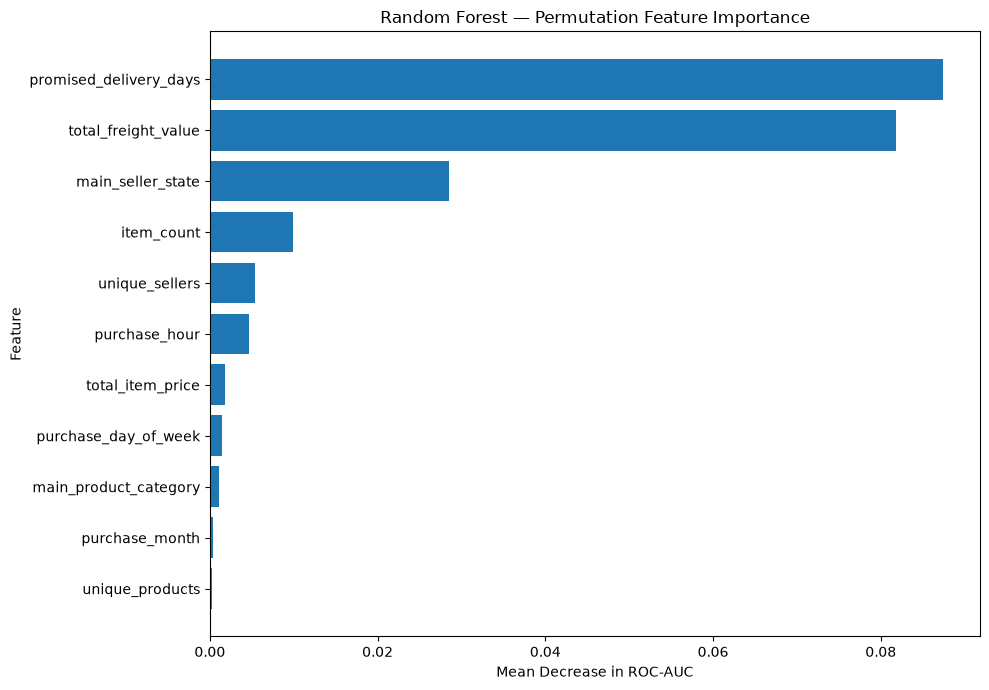

In [65]:
# Sort features for plotting
importance_plot = feature_importance_time.sort_values(
    "Importance_Mean",
    ascending=True
)

# Create the horizontal bar chart
plt.figure(figsize=(10, 7))

plt.barh(
    importance_plot["Feature"],
    importance_plot["Importance_Mean"]
)

plt.title("Random Forest — Permutation Feature Importance")
plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [66]:
# Import joblib for saving the model
import joblib

# Bundle the model, threshold, and feature schema
model_bundle = {
    "model": rf_time_model,
    "threshold": chosen_threshold,
    "feature_columns": feature_columns,
    "target_name": "late_delivery"
}

# Save the bundle to a file
joblib.dump(
    model_bundle,
    "olist_late_delivery_model_final.joblib"
)

print("Final model bundle saved successfully.")

Final model bundle saved successfully.


In [67]:
# Check whether Streamlit is installed
import importlib.util

if importlib.util.find_spec("streamlit") is None:
    print("Streamlit is not installed in this environment.")
    print("If permitted, install it using: %pip install streamlit")
else:
    print("Streamlit is available.")

Streamlit is available.


In [68]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

# Configure the page
st.set_page_config(
    page_title="Olist Late Delivery Risk",
    page_icon="📦",
    layout="centered"
)

# Load the saved model bundle
@st.cache_resource
def load_model_bundle():
    return joblib.load("olist_late_delivery_model_final.joblib")

bundle = load_model_bundle()

model = bundle["model"]
threshold = bundle["threshold"]

# Application title and description
st.title("Olist Late Delivery Risk Prediction")

st.write(
    "Enter the order features below to estimate the model's "
    "predicted late-delivery probability."
)

st.warning(
    "Demonstration only: this model was trained on delivered orders "
    "and has not been validated for operational predictions on "
    "orders currently in transit."
)

# Collect numeric features
st.subheader("Order Information")

purchase_month = st.selectbox(
    "Purchase month",
    list(range(1, 13)),
    index=0
)

purchase_day_of_week = st.selectbox(
    "Purchase day of week (0 = Monday)",
    list(range(7)),
    index=0
)

purchase_hour = st.slider(
    "Purchase hour",
    min_value=0,
    max_value=23,
    value=12
)

promised_delivery_days = st.number_input(
    "Promised delivery days",
    min_value=0.0,
    value=15.0,
    step=1.0
)

item_count = st.number_input(
    "Number of items",
    min_value=1,
    value=1,
    step=1
)

total_item_price = st.number_input(
    "Total item price",
    min_value=0.0,
    value=100.0,
    step=10.0
)

total_freight_value = st.number_input(
    "Total freight value",
    min_value=0.0,
    value=20.0,
    step=5.0
)

unique_sellers = st.number_input(
    "Number of unique sellers",
    min_value=1,
    value=1,
    step=1
)

unique_products = st.number_input(
    "Number of unique products",
    min_value=1,
    value=1,
    step=1
)

# Collect categorical features
st.subheader("Product and Seller Information")

main_product_category = st.text_input(
    "Main product category",
    value="bed_bath_table",
    help="Enter a category value represented in the training data."
)

main_seller_state = st.text_input(
    "Main seller state",
    value="SP",
    help="Enter a seller-state code represented in the training data."
)

# Make a prediction when the user clicks the button
if st.button("Predict Delivery Risk"):

    # Create a single-row DataFrame using the expected feature names
    input_data = pd.DataFrame([{
        "purchase_month": purchase_month,
        "purchase_day_of_week": purchase_day_of_week,
        "purchase_hour": purchase_hour,
        "promised_delivery_days": promised_delivery_days,
        "item_count": item_count,
        "total_item_price": total_item_price,
        "total_freight_value": total_freight_value,
        "unique_sellers": unique_sellers,
        "unique_products": unique_products,
        "main_product_category": main_product_category,
        "main_seller_state": main_seller_state
    }])

    # Ensure the feature order matches the saved schema
    input_data = input_data[bundle["feature_columns"]]

    # Calculate the probability of late delivery
    late_probability = model.predict_proba(input_data)[0, 1]

    # Apply the threshold selected during validation
    predicted_late = late_probability >= threshold

    st.subheader("Prediction Result")

    st.metric(
        "Predicted late-delivery probability",
        f"{late_probability:.1%}"
    )

    st.caption(f"Classification threshold: {threshold:.2f}")

    if predicted_late:
        st.error("The model classifies this order as late-delivery risk.")
    else:
        st.success("The model classifies this order as not flagged for late-delivery risk.")

    st.progress(float(late_probability))

    st.caption(
        "This is a model estimate, not a guarantee that an order "
        "will arrive late or on time."
    )

Writing app.py


In [ ]:
!streamlit run app.py



2026-10-27 07:26:20.670 Uvicorn server started on :::8503

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8503
  Network URL: http://10.0.0.211:8503
  External URL: http://10.0.0.211:8503



In [ ]:
!streamlit run app.py --server.port 8503 --server.address 0.0.0.0